# Dermatological Disease Classification

**Data-Centric AI Course**

**Lorenzo Antonioli**

# 1. Business Understanding

The objective of this project is to develop a classification model capable of identifying different dermatological diseases based on clinical and histopathological features collected from patients.

The project focuses on the analysis of dermatological data and the identification of patterns that can help distinguish between six different skin diseases. Particular attention will be given to data quality, data preparation and feature optimization, investigating how data-centric techniques can improve the reliability and performance of machine learning models.

The main goal is to assess the impact of data quality improvements on classification performance, comparing different data preparation strategies and evaluating their effectiveness.

# 2. Data Understanding

This phase aims to gain a deeper understanding of the dataset, examining its structure, features and statistical properties. The analysis focuses on identifying the characteristics of the available data, understanding the distribution of the target variable and detecting potential data quality issues that may affect subsequent analysis and modeling.

## 2.1 Dataset Overview

The dataset used in this project is the [Dermatology Dataset](https://www.kaggle.com/datasets/olcaybolat1/dermatology-dataset-classification), originally obtained from the UCI Machine Learning Repository.

It consists of 366 patient records, 34 predictive features and one target variable representing the dermatological diagnosis. The features describe clinical and histopathological characteristics, providing information about the symptoms and microscopic properties associated with different skin diseases.

The dataset addresses a six-class classification problem, with each instance assigned to one of the following dermatological conditions:

- Psoriasis
- Seborrheic Dermatitis
- Lichen Planus
- Pityriasis Rosea
- Chronic Dermatitis
- Pityriasis Rubra Pilaris

The included variables are:

- `erythema`: Degree of skin redness.
- `scaling`: Degree of skin scaling.
- `definite_borders`: Presence and degree of well-defined lesion borders.
- `itching`: Degree of itching experienced by the patient.
- `koebner_phenomenon`: Presence of the Koebner phenomenon.
- `polygonal_papules`: Presence of polygonal papules.
- `follicular_papules`: Presence of follicular papules.
- `oral_mucosal_involvement`: Presence of oral mucosal involvement.
- `knee_and_elbow_involvement`: Presence of lesions on knees and elbows.
- `scalp_involvement`: Presence of scalp lesions.
- `family_history`: Presence of a family history of the disease.
- `melanin_incontinence`: Presence of melanin incontinence.
- `eosinophils_infiltrate`: Presence of eosinophils in the infiltrate.
- `PNL_infiltrate`: Presence of polymorphonuclear leukocytes in the infiltrate.
- `fibrosis_papillary_dermis`: Presence of fibrosis in the papillary dermis.
- `exocytosis`: Presence of exocytosis.
- `acanthosis`: Presence of acanthosis.
- `hyperkeratosis`: Presence of hyperkeratosis.
- `parakeratosis`: Presence of parakeratosis.
- `clubbing_rete_ridges`: Presence of clubbing of rete ridges.
- `elongation_rete_ridges`: Elongation of rete ridges.
- `thinning_suprapapillary_epidermis`: Thinning of the suprapapillary epidermis.
- `spongiform_pustule`: Presence of spongiform pustules.
- `munro_microabcess`: Presence of Munro microabscesses.
- `focal_hypergranulosis`: Presence of focal hypergranulosis.
- `disappearance_granular_layer`: Disappearance of the granular layer.
- `vacuolisation_damage_basal_layer`: Presence of basal layer vacuolisation.
- `spongiosis`: Presence of spongiosis.
- `saw_tooth_appearance_retes`: Presence of saw-tooth-shaped rete ridges.
- `follicular_horn_plug`: Presence of follicular horn plugs.
- `perifollicular_parakeratosis`: Presence of perifollicular parakeratosis.
- `inflammatory_mononuclear_infiltrate`: Presence of inflammatory mononuclear infiltrate.
- `band_like_infiltrate`: Presence of band-like inflammatory infiltrate.
- `age`: Patient's age.

Most clinical and histopathological features are ordinal
variables encoded with integer values ranging from 0 to 3.
The `family_history` attribute is binary, taking values
of 0 or 1, while `age` is a numerical variable expressed
in years.

The target variable is:

- `class`: Dermatological diagnosis, represented by six different disease categories.



In [28]:
# Libraries import
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from functools import partial

from sklearn.base import clone
from sklearn.feature_selection import (
    VarianceThreshold,
    SelectKBest,
    mutual_info_classif,
    RFE,
    SequentialFeatureSelector
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.metrics import balanced_accuracy_score, f1_score, accuracy_score

In [3]:
warnings.filterwarnings('ignore')

csv_url = 'https://raw.githubusercontent.com/lolloantonioli/dermatology-disease-classification/refs/heads/main/dermatology_database_1.csv'

# Dataset download
try:
    df = pd.read_csv(csv_url)
    print('Dataset downloaded successfully')
    print(f'The dataset contains {df.shape[0]} rows and {df.shape[1]} columns')
    display(df.head())
    display(df.tail())
    df.info()
except FileNotFoundError:
    print('Error: File not found')

Dataset downloaded successfully
The dataset contains 366 rows and 35 columns


,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,disappearance_granular_layer,vacuolisation_damage_basal_layer,spongiosis,saw_tooth_appearance_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_mononuclear_infiltrate,band_like_infiltrate,age,class
0,2,2,0,3,0,0,0,0,1,0,...,0,0,3,0,0,0,1,0,55,2
1,3,3,3,2,1,0,0,0,1,1,...,0,0,0,0,0,0,1,0,8,1
2,2,1,2,3,1,3,0,3,0,0,...,0,2,3,2,0,0,2,3,26,3
3,2,2,2,0,0,0,0,0,3,2,...,3,0,0,0,0,0,3,0,40,1
4,2,3,2,2,2,2,0,2,0,0,...,2,3,2,3,0,0,2,3,45,3


,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,disappearance_granular_layer,vacuolisation_damage_basal_layer,spongiosis,saw_tooth_appearance_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_mononuclear_infiltrate,band_like_infiltrate,age,class
361,2,1,1,0,1,0,0,0,0,0,...,0,0,1,0,0,0,2,0,25,4
362,3,2,1,0,1,0,0,0,0,0,...,1,0,1,0,0,0,2,0,36,4
363,3,2,2,2,3,2,0,2,0,0,...,0,3,0,3,0,0,2,3,28,3
364,2,1,3,1,2,3,0,2,0,0,...,0,2,0,1,0,0,2,3,50,3
365,3,2,2,0,0,0,0,0,3,3,...,2,0,0,0,0,0,3,0,35,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 366 entries, 0 to 365
Data columns (total 35 columns):
 #   Column                               Non-Null Count  Dtype 
---  ------                               --------------  ----- 
 0   erythema                             366 non-null    int64 
 1   scaling                              366 non-null    int64 
 2   definite_borders                     366 non-null    int64 
 3   itching                              366 non-null    int64 
 4   koebner_phenomenon                   366 non-null    int64 
 5   polygonal_papules                    366 non-null    int64 
 6   follicular_papules                   366 non-null    int64 
 7   oral_mucosal_involvement             366 non-null    int64 
 8   knee_and_elbow_involvement           366 non-null    int64 
 9   scalp_involvement                    366 non-null    int64 
 10  family_history                       366 non-null    int64 
 11  melanin_incontinence                 366 non-

In [4]:
print("Feature Categories:")

clinical_features = ['erythema', 'scaling', 'definite_borders', 'itching', 'koebner_phenomenon',
                     'polygonal_papules', 'follicular_papules', 'oral_mucosal_involvement',
                     'knee_and_elbow_involvement', 'scalp_involvement', 'family_history']

histopathological_features = ['melanin_incontinence', 'eosinophils_infiltrate', 'PNL_infiltrate',
                              'fibrosis_papillary_dermis', 'exocytosis', 'acanthosis', 'hyperkeratosis',
                              'parakeratosis', 'clubbing_rete_ridges', 'elongation_rete_ridges',
                              'thinning_suprapapillary_epidermis', 'spongiform_pustule', 'munro_microabcess',
                              'focal_hypergranulosis', 'disappearance_granular_layer',
                              'vacuolisation_damage_basal_layer', 'spongiosis', 'saw_tooth_appearance_retes',
                              'follicular_horn_plug', 'perifollicular_parakeratosis',
                              'inflammatory_mononuclear_infiltrate', 'band_like_infiltrate']

print(f"Clinical Features (visible symptoms): {len(clinical_features)}")
print(f"Histopathological Features (microscopic): {len(histopathological_features)}")

Feature Categories:
Clinical Features (visible symptoms): 11
Histopathological Features (microscopic): 22


This cell categorizes features into clinical and histopatological. This distinction is medically relevant because clinical features are easier to obtain.

## 2.2 Missing Values Analysis

Missing values can affect the reliability of statistical analyses and machine learning models. This subsection investigates the presence and distribution of missing values across the dataset.

Since the dataset documentation identifies the ? symbol as the representation of missing values in the age attribute, these values must be explicitly identified and converted into a standard missing-value representation before performing further analysis.

In [5]:
df_analysis = df.copy()
df_analysis['age'] = df_analysis['age'].replace('?', np.nan)
df_analysis['age'] = pd.to_numeric(df_analysis['age'])
missing_values = pd.DataFrame({
    'Missing Values': df_analysis.isnull().sum(),
    'Percentage (%)': df_analysis.isnull().mean() * 100
})

missing_values = missing_values[missing_values['Missing Values'] > 0]

display(missing_values)

,Missing Values,Percentage (%)
age,8,2.185792


The missing values analysis identifies 8 missing observations in the age attribute, corresponding to approximately 2.19% of the dataset.

No missing values are detected in the remaining attributes.

The missing values are represented by the ? symbol in the original dataset and have been converted into the standard NaN representation to enable further analysis.

Since the missing proportion is relatively limited and concerns only one numerical attribute, it is unlikely to compromise the overall usability of the dataset. Nevertheless, an appropriate imputation strategy will need to be evaluated during the Data Preparation phase.

## 2.3 Age Analysis

Age Statistical Summary Table


Metric,Value
Mean,36.30
Standard Deviation,15.32
Minimum,0.00
25th Percentile (Q1),25.00
Median (50th Percentile),35.00
75th Percentile (Q3),49.75
Maximum,75.00
Mode,40.00
Kurtosis,-0.71
Skewness,0.07


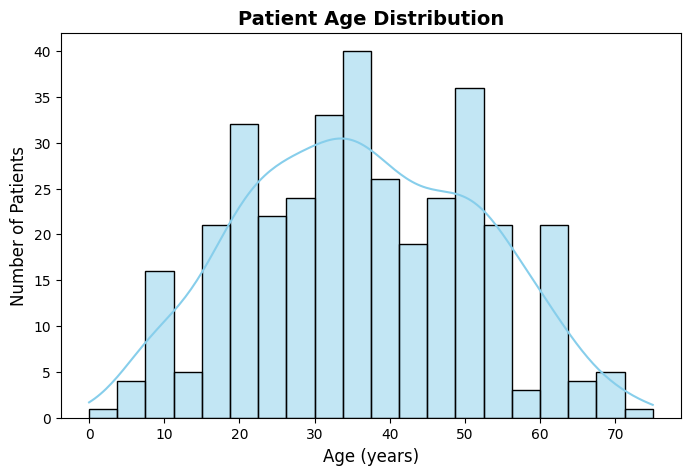

In [6]:
# Compute individual metrics for the age feature
age_series = df_analysis['age']
desc = df_analysis['age'].describe()

# Extract individual statistics and format them to exactly 2 decimal places
metrics = {
    'Metric': [
        'Mean', 'Standard Deviation', 'Minimum', '25th Percentile (Q1)',
        'Median (50th Percentile)', '75th Percentile (Q3)', 'Maximum',
        'Mode', 'Kurtosis', 'Skewness'
    ],
    'Value': [
        f"{desc['mean']:.2f}",
        f"{desc['std']:.2f}",
        f"{desc['min']:.2f}",
        f"{desc['25%']:.2f}",
        f"{age_series.median():.2f}",
        f"{desc['75%']:.2f}",
        f"{desc['max']:.2f}",
        f"{age_series.mode().iloc[0]:.2f}" if not age_series.mode().empty else "None",
        f"{age_series.kurtosis():.2f}",
        f"{age_series.skew():.2f}"
    ]
}

# Create a unified DataFrame for visualization
stats_table = pd.DataFrame(metrics)

print('Age Statistical Summary Table')
# Display the DataFrame without the index column for clean visualization
display(stats_table.style.hide(axis='index'))

# Age distribution - Histogram
plt.figure(figsize=(8, 5))
sns.histplot(df_analysis['age'], kde=True, color='skyblue', bins=20, edgecolor='black')
plt.title("Patient Age Distribution", fontsize=14, fontweight='bold')
plt.xlabel("Age (years)", fontsize=12)

plt.ylabel("Number of Patients", fontsize=12)
plt.show()

The descriptive statistical analysis and visualization of the patients' age distribution reveal the following observations:

- **Mean and Median Age**: The mean age of the patients is **36.30 years**, which is very close to the median of **35.00 years**. This proximity suggests that the age distribution is relatively balanced.

- **Dispersion and Range**: The standard deviation of **15.32 years** indicates a moderate degree of variability in the data. Patients' ages span a wide range, from a minimum of **0 years** (including pediatric or neonatal patients) to a maximum of **75 years**.

- **Distribution Shape (Skewness and Kurtosis)**:
  - The **Skewness** value of **0.07** mathematically confirms that the distribution is almost perfectly symmetric around its center.
  - The **Kurtosis** value of **-0.71** indicates a platykurtic distribution, characterized by a flatter shape and lighter tails compared to a normal distribution.

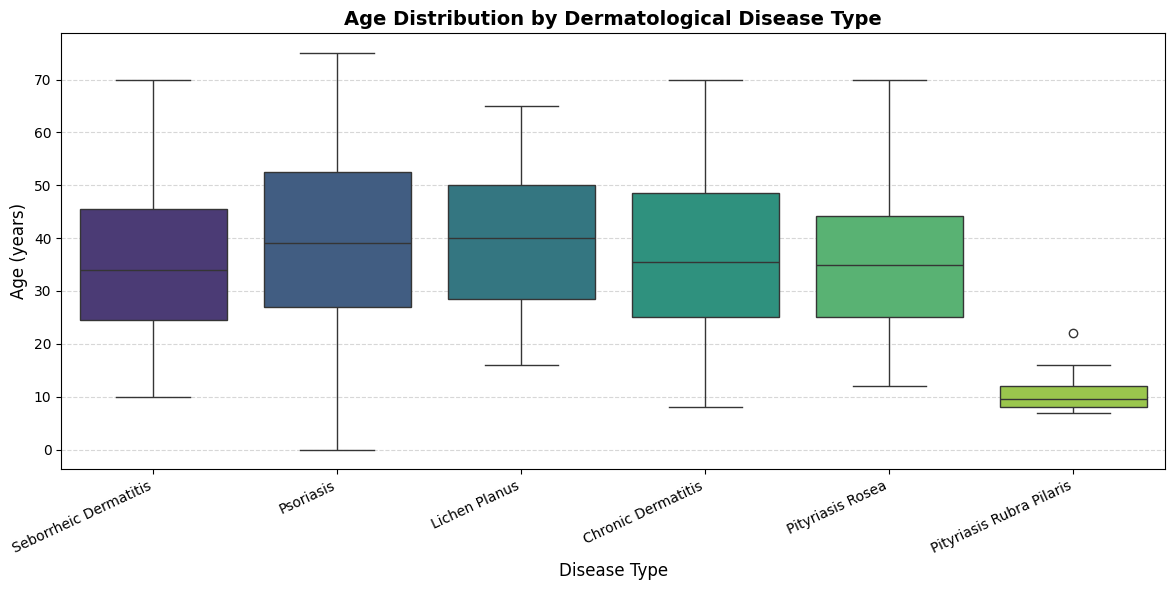

In [7]:
# Map numerical classes to disease names for clearer plotting
class_map = {
    1: 'Psoriasis',
    2: 'Seborrheic Dermatitis',
    3: 'Lichen Planus',
    4: 'Pityriasis Rosea',
    5: 'Chronic Dermatitis',
    6: 'Pityriasis Rubra Pilaris'
}

df_plot = df_analysis.copy()
df_plot['disease_type'] = df_plot['class'].map(class_map)

# Visualization: Age distribution by disease type
plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df_plot,
    x='disease_type',
    y='age',
    palette='viridis'
)

plt.title('Age Distribution by Dermatological Disease Type', fontsize=14, fontweight='bold')
plt.xlabel('Disease Type', fontsize=12)
plt.ylabel('Age (years)', fontsize=12)
plt.xticks(rotation=25, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

This analysis explores how the age of patients varies across the six different dermatological conditions present in the dataset:

- **Significant Age Differences**: There are clear differences in age ranges across different conditions. For instance, **Pityriasis Rubra Pilaris** (Class 6) is highly concentrated among very young pediatric patients (with a median age close to 10 years).
- **Adult Prevalence**: Conditions like **Psoriasis**, **Seborrheic Dermatitis**, **Lichen Planus**, and **Chronic Dermatitis** primarily affect adults, showing median ages spanning from roughly 35 to 40 years. This indicates that the patients belonging to these disease categories are predominantly adults within the analyzed dataset.
- **Wider Distributions**: **Psoriasis** and **Chronic Dermatitis** show the widest spread of patient ages, indicating that these diseases can manifest across almost any age group from early adulthood to elderly patients.

## 2.4 Duplicate Detection

Duplicate records may introduce unwanted bias into the dataset, as repeated observations can disproportionately influence the learning process of machine learning algorithms.

This analysis identifies exact duplicate records by comparing all attributes and determines whether duplicate removal is necessary.

In [8]:
n_duplicates = df_analysis.duplicated().sum()

print(f"Number of duplicate records: {n_duplicates}")
print(f"Percentage of duplicates: {n_duplicates / len(df_analysis) * 100:.2f}%")

Number of duplicate records: 0
Percentage of duplicates: 0.00%


## 2.5 Statistical Profiling

Statistical profiling provides an overview of the numerical properties of the dataset, helping identify distributions, variability and potential anomalies.

Descriptive statistics are calculated to examine the central tendency, dispersion and range of each attribute. Since most predictive features are ordinal variables, their distributions and frequency of individual values are also relevant for understanding the dataset.

In [9]:
# Descriptive statistics
display(df_analysis.describe().T)

# Frequency distribution of ordinal features
ordinal_features = [
    col for col in df_analysis.columns
    if col not in ['age', 'class', 'family_history']
]

# Count the occurrences of each ordinal value
ordinal_frequencies = pd.DataFrame({
    col: df_analysis[col].value_counts(normalize=True).sort_index()
    for col in ordinal_features
}).T

display(ordinal_frequencies)

,count,mean,std,min,25%,50%,75%,max
erythema,366.0,2.068306,0.664753,0.0,2.0,2.0,2.00,3.0
scaling,366.0,1.795082,0.701527,0.0,1.0,2.0,2.00,3.0
definite_borders,366.0,1.549180,0.907525,0.0,1.0,2.0,2.00,3.0
itching,366.0,1.366120,1.138299,0.0,0.0,1.0,2.00,3.0
koebner_phenomenon,366.0,0.633880,0.908016,0.0,0.0,0.0,1.00,3.0
polygonal_papules,366.0,0.448087,0.957327,0.0,0.0,0.0,0.00,3.0
follicular_papules,366.0,0.166667,0.570588,0.0,0.0,0.0,0.00,3.0
oral_mucosal_involvement,366.0,0.377049,0.834147,0.0,0.0,0.0,0.00,3.0
knee_and_elbow_involvement,366.0,0.614754,0.982979,0.0,0.0,0.0,1.00,3.0
scalp_involvement,366.0,0.519126,0.905639,0.0,0.0,0.0,1.00,3.0


,0,1,2,3
erythema,0.010929,0.155738,0.587432,0.245902
scaling,0.021858,0.303279,0.532787,0.142077
definite_borders,0.161202,0.254098,0.459016,0.125683
itching,0.322404,0.196721,0.273224,0.207650
koebner_phenomenon,0.612022,0.191257,0.147541,0.049180
polygonal_papules,0.811475,0.002732,0.112022,0.073770
follicular_papules,0.909836,0.030055,0.043716,0.016393
oral_mucosal_involvement,0.816940,0.024590,0.122951,0.035519
knee_and_elbow_involvement,0.685792,0.076503,0.174863,0.062842
scalp_involvement,0.721311,0.081967,0.153005,0.043716


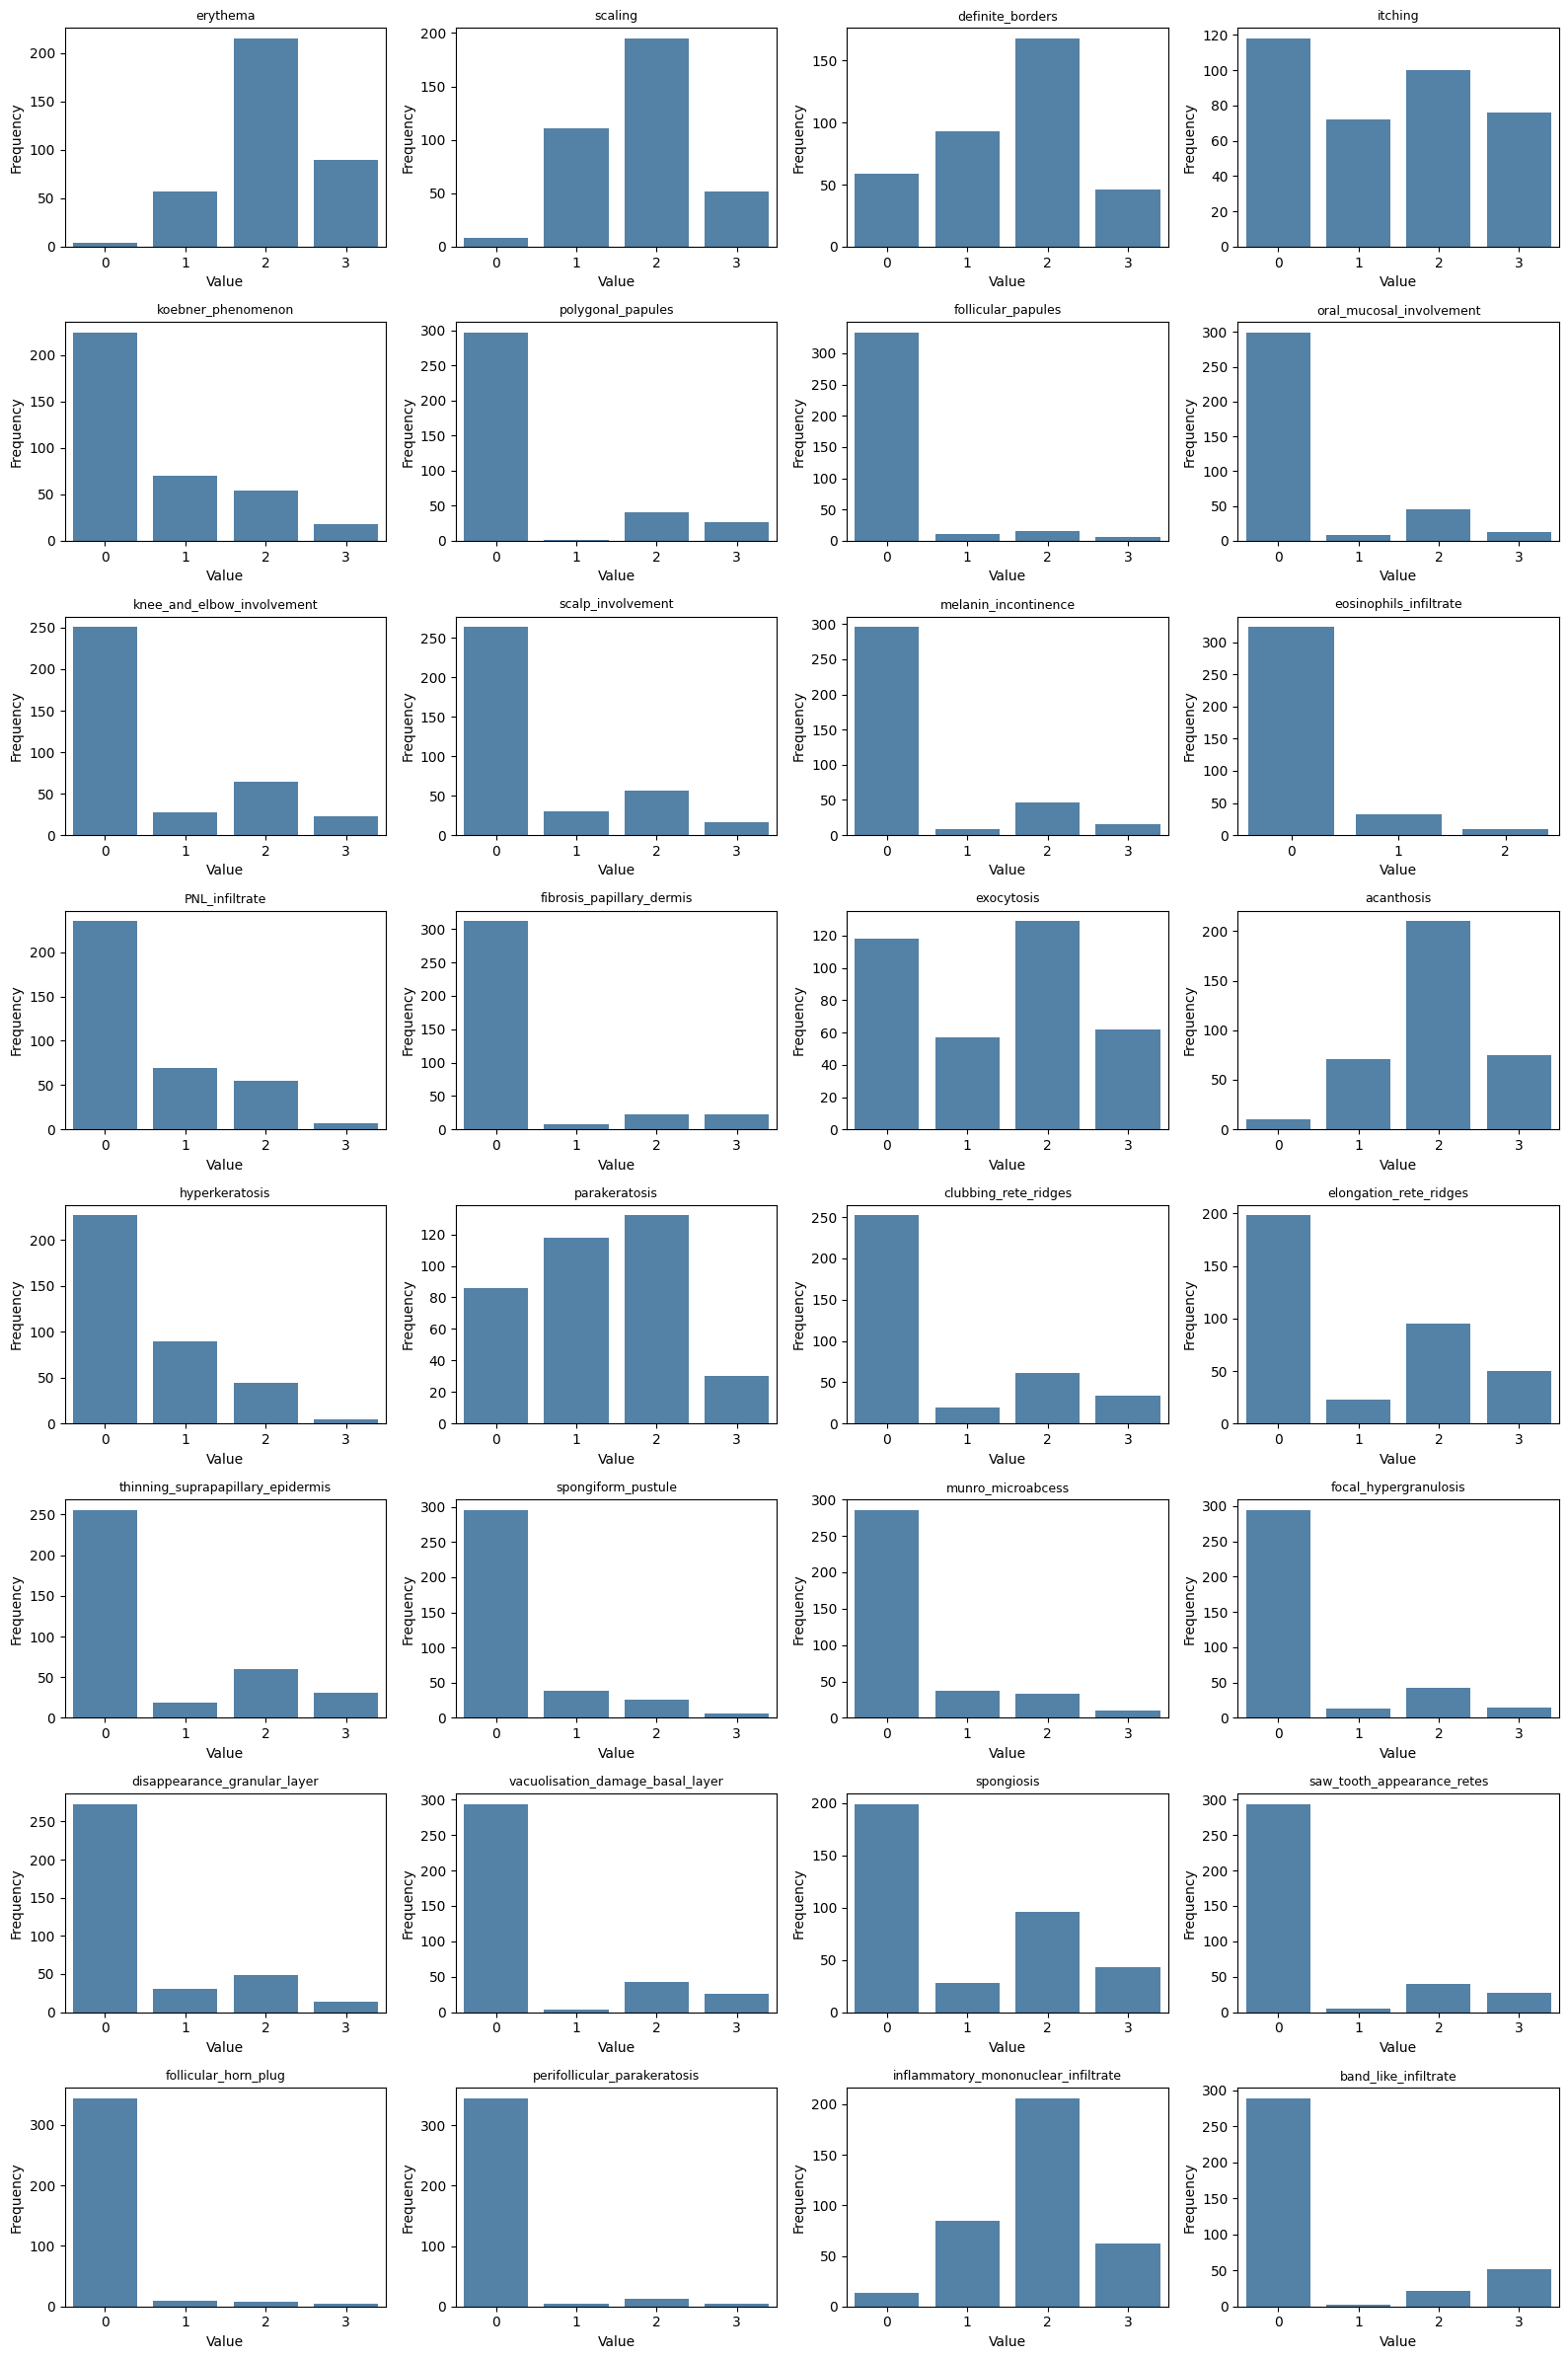

In [10]:
# Plot distributions of ordinal features
n_cols = 4
n_rows = int(np.ceil(len(ordinal_features) / n_cols))

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(16, n_rows * 3)
)

axes = axes.flatten()

for i, col in enumerate(ordinal_features):
    sns.countplot(
        data=df_analysis,
        x=col,
        ax=axes[i],
        color='steelblue'
    )

    axes[i].set_title(col, fontsize=9)
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')

# Remove unused subplots
for i in range(len(ordinal_features), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

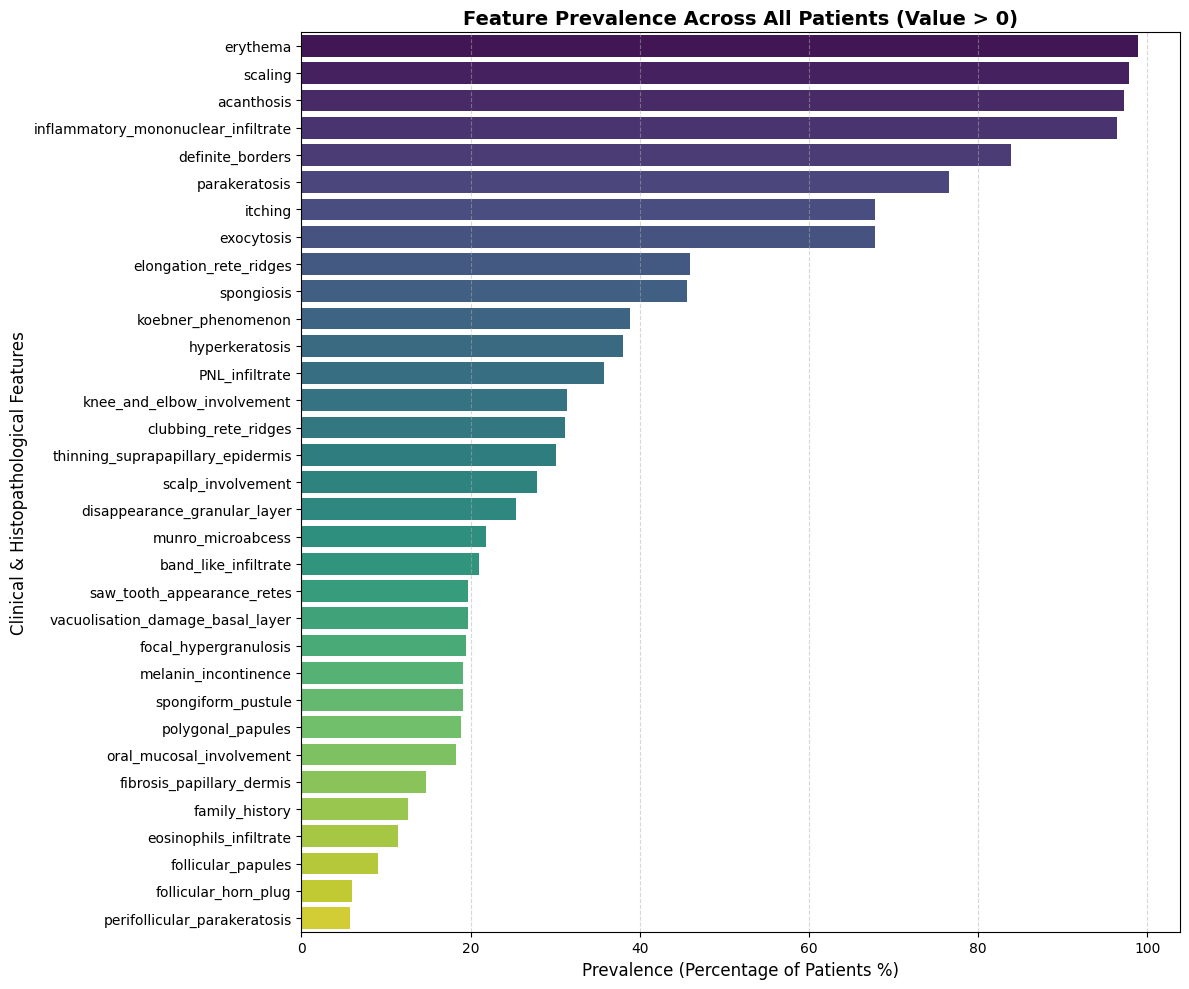

In [11]:
# Combine clinical and histopathological features
features_to_analyze = clinical_features + histopathological_features

# Calculate the prevalence of each feature (percentage of patients with value > 0)
prevalence = (df_analysis[features_to_analyze] > 0).mean() * 100
prevalence_df = pd.DataFrame({
    'Feature': prevalence.index,
    'Prevalence (%)': prevalence.values
}).sort_values(by='Prevalence (%)', ascending=False)

# Visualization: Feature Prevalence
plt.figure(figsize=(12, 10))
sns.barplot(
    data=prevalence_df,
    x='Prevalence (%)',
    y='Feature',
    palette='viridis'
)

plt.title('Feature Prevalence Across All Patients (Value > 0)', fontsize=14, fontweight='bold')
plt.xlabel('Prevalence (Percentage of Patients %)', fontsize=12)
plt.ylabel('Clinical & Histopathological Features', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

This section profiles the central tendency and value frequencies across our clinical and histopathological predictive features:

- **Dominant Absence of Certain Features**: Many ordinal features are highly dominated by `0`, indicating that they are completely absent in the vast majority of patients. For example, features like `perifollicular_parakeratosis` and `follicular_horn_plug` are absent (`0`) in over 94% of the patients.
- **Highly Prevalent Clinical Symptoms**: On the other hand, fundamental clinical symptoms like `erythema` (skin redness) and `scaling` are highly prevalent, appearing in nearly 98-99% of patients. Furthermore, erythema predominantly exhibits values of 2 or 3 (83.33% of observations), while scaling shows a similar concentration in these categories (67.49%).
- **Feature Sparsity**: This extreme imbalance in ordinal value distributions (where many features are almost always 0) highlights that several features are highly specific to specific sub-categories of diseases, rather than being generalized indicators across all patient classes.

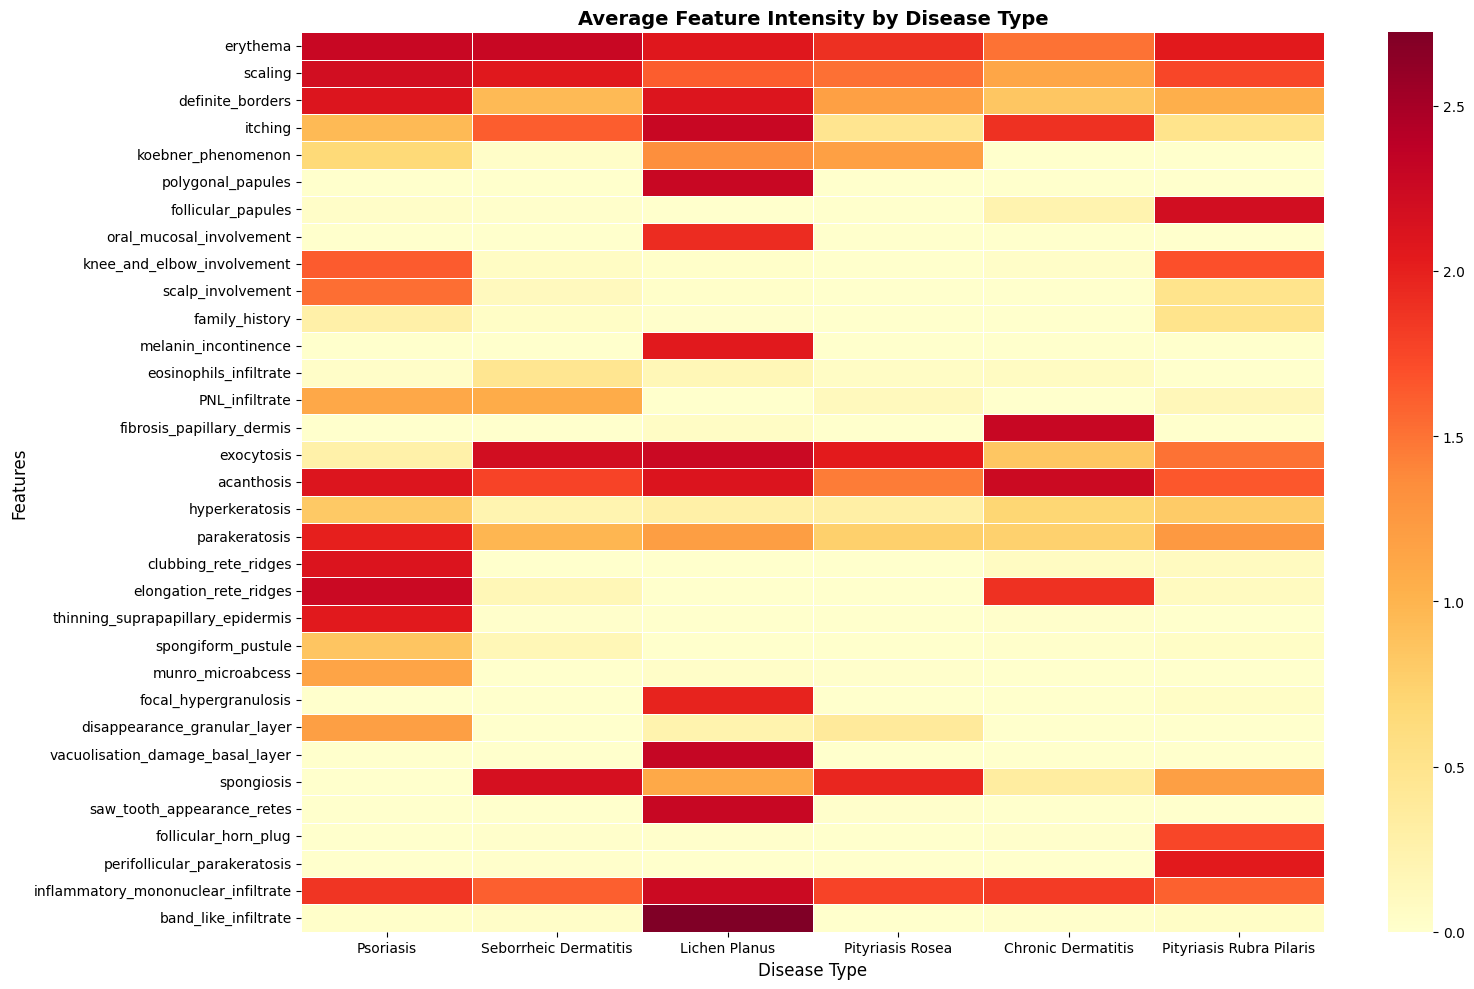

In [12]:
# Calculate mean feature values for each disease class
feature_cols = clinical_features + histopathological_features
feature_means = df_analysis.groupby('class')[feature_cols].mean()

# Map the numeric class index to the actual disease names using the existing class_map
feature_means.index = [class_map[i] for i in feature_means.index]

# Plot the heatmap
fig, ax = plt.subplots(figsize=(16, 10))
sns.heatmap(
    feature_means.T,
    annot=False,
    cmap='YlOrRd',
    linewidths=0.5,
    ax=ax
)

ax.set_title('Average Feature Intensity by Disease Type', fontsize=14, fontweight='bold')
ax.set_xlabel('Disease Type', fontsize=12)
ax.set_ylabel('Features', fontsize=12)
plt.tight_layout()
plt.show()

The heatmap visualizes the average intensity of clinical and histopathological features grouped by disease type, highlighting the following observations:

- **Disease-Specific Signatures**: Each disease exhibits a distinctive combination of clinical and histopathological feature intensities. In particular, **Lichen Planus** shows high average values for features such as `polygonal_papules`, `oral_mucosal_involvement`, `melanin_incontinence`, and `band_like_infiltrate`. These patterns suggest the presence of characteristic feature profiles associated with specific disease categories.
- **Psoriasis Characteristics**: **Psoriasis** exhibits particularly high average values for `clubbing_rete_ridges`, `elongation_rete_ridges`, and `thinning_suprapapillary_epidermis`. These histopathological features represent distinctive patterns within this disease category and may contribute to its differentiation from other conditions.
- **Shared vs. Disease-Specific Characteristics**: Some clinical symptoms, particularly `erythema` and `scaling`, exhibit relatively high average values across multiple disease categories, suggesting that they are common characteristics within the dataset. Conversely, several histopathological features display more specialized distributions, with higher average values in specific disease categories.

Overall, the heatmap highlights substantial differences in the average feature profiles across dermatological conditions. In particular, histopathological attributes appear to provide potentially discriminative information, while several clinical symptoms are shared across multiple disease categories. These observations suggest that combining clinical and histopathological features may be important for distinguishing between the different conditions.

## 2.6 Target Variable Distribution

The target variable distribution is examined to understand the representation of each dermatological disease within the dataset.

Class imbalance is particularly relevant in multiclass classification problems, as underrepresented classes may receive less attention during model training, potentially leading to biased predictions and lower classification performance for minority classes.

,Number of Instances,Percentage (%)
Psoriasis,112,30.601093
Seborrheic Dermatitis,61,16.666667
Lichen Planus,72,19.672131
Pityriasis Rosea,49,13.387978
Chronic Dermatitis,52,14.207650
Pityriasis Rubra Pilaris,20,5.464481


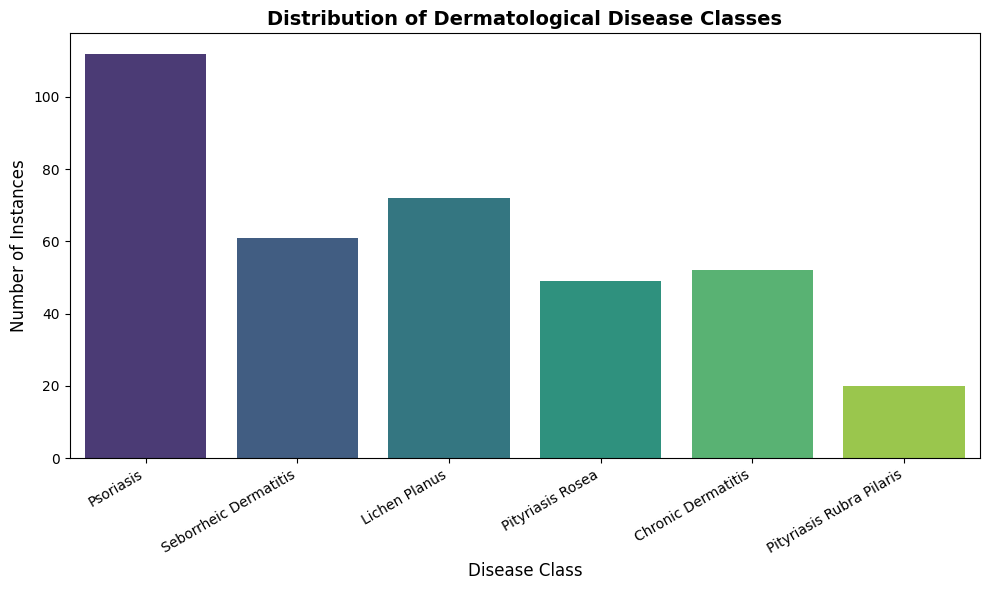

In [13]:
# Define the disease name labels for the classes 1 to 6
class_names = [
    'Psoriasis',
    'Seborrheic Dermatitis',
    'Lichen Planus',
    'Pityriasis Rosea',
    'Chronic Dermatitis',
    'Pityriasis Rubra Pilaris'
]

# Class distribution
class_counts = df_analysis['class'].value_counts().sort_index()

class_distribution = pd.DataFrame({
    'Number of Instances': class_counts,
    'Percentage (%)': class_counts / len(df_analysis) * 100
})

# Assign class names as the index of the DataFrame for better readability
class_distribution.index = class_names

display(class_distribution)

# Visualization
plt.figure(figsize=(10, 6))

sns.barplot(
    x=class_distribution.index,
    y=class_distribution['Number of Instances'],
    palette='viridis'
)

plt.title('Distribution of Dermatological Disease Classes', fontsize=14, fontweight='bold')
plt.xlabel('Disease Class', fontsize=12)
plt.ylabel('Number of Instances', fontsize=12)
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

The analysis of the target variable reveals an uneven distribution across the six dermatological disease categories, highlighting the following observations:

- **Largest Class**: **Psoriasis** is the most represented disease category, accounting for 112 observations (30.60% of the dataset).
- **Smallest Class**: **Pityriasis Rubra Pilaris** is the least represented category, with only 20 observations (5.46%). This represents a considerably smaller number of instances compared to the other classes.
- **Class Imbalance**: The distribution exhibits a noticeable class imbalance. The largest class (Psoriasis) contains approximately 5.6 times as many observations as the smallest class (Pityriasis Rubra Pilaris).
- **Distribution Across Remaining Classes**: The other four categories show intermediate representation, with percentages ranging from approximately 13.39% to 19.67%.

Overall, the dataset presents a multiclass imbalance problem, particularly due to the limited representation of Pityriasis Rubra Pilaris. This may affect the learning process and lead to lower predictive performance for underrepresented categories. Therefore, class imbalance should be taken into consideration during the Data Preparation phase, where sampling and resampling techniques may be investigated. Furthermore, evaluation metrics such as macro-averaged precision, recall and F1-score will be important to ensure that model performance is assessed fairly across all disease categories.

## 2.8 Correlation Analysis

Correlation analysis investigates the relationships between predictive features and their potential association with the target variable.

Since most attributes are ordinal, Spearman's rank correlation coefficient is used. Unlike Pearson correlation, Spearman correlation evaluates monotonic relationships based on ranked values.

A correlation matrix is generated to identify groups of potentially related features and investigate possible redundancy within the dataset.

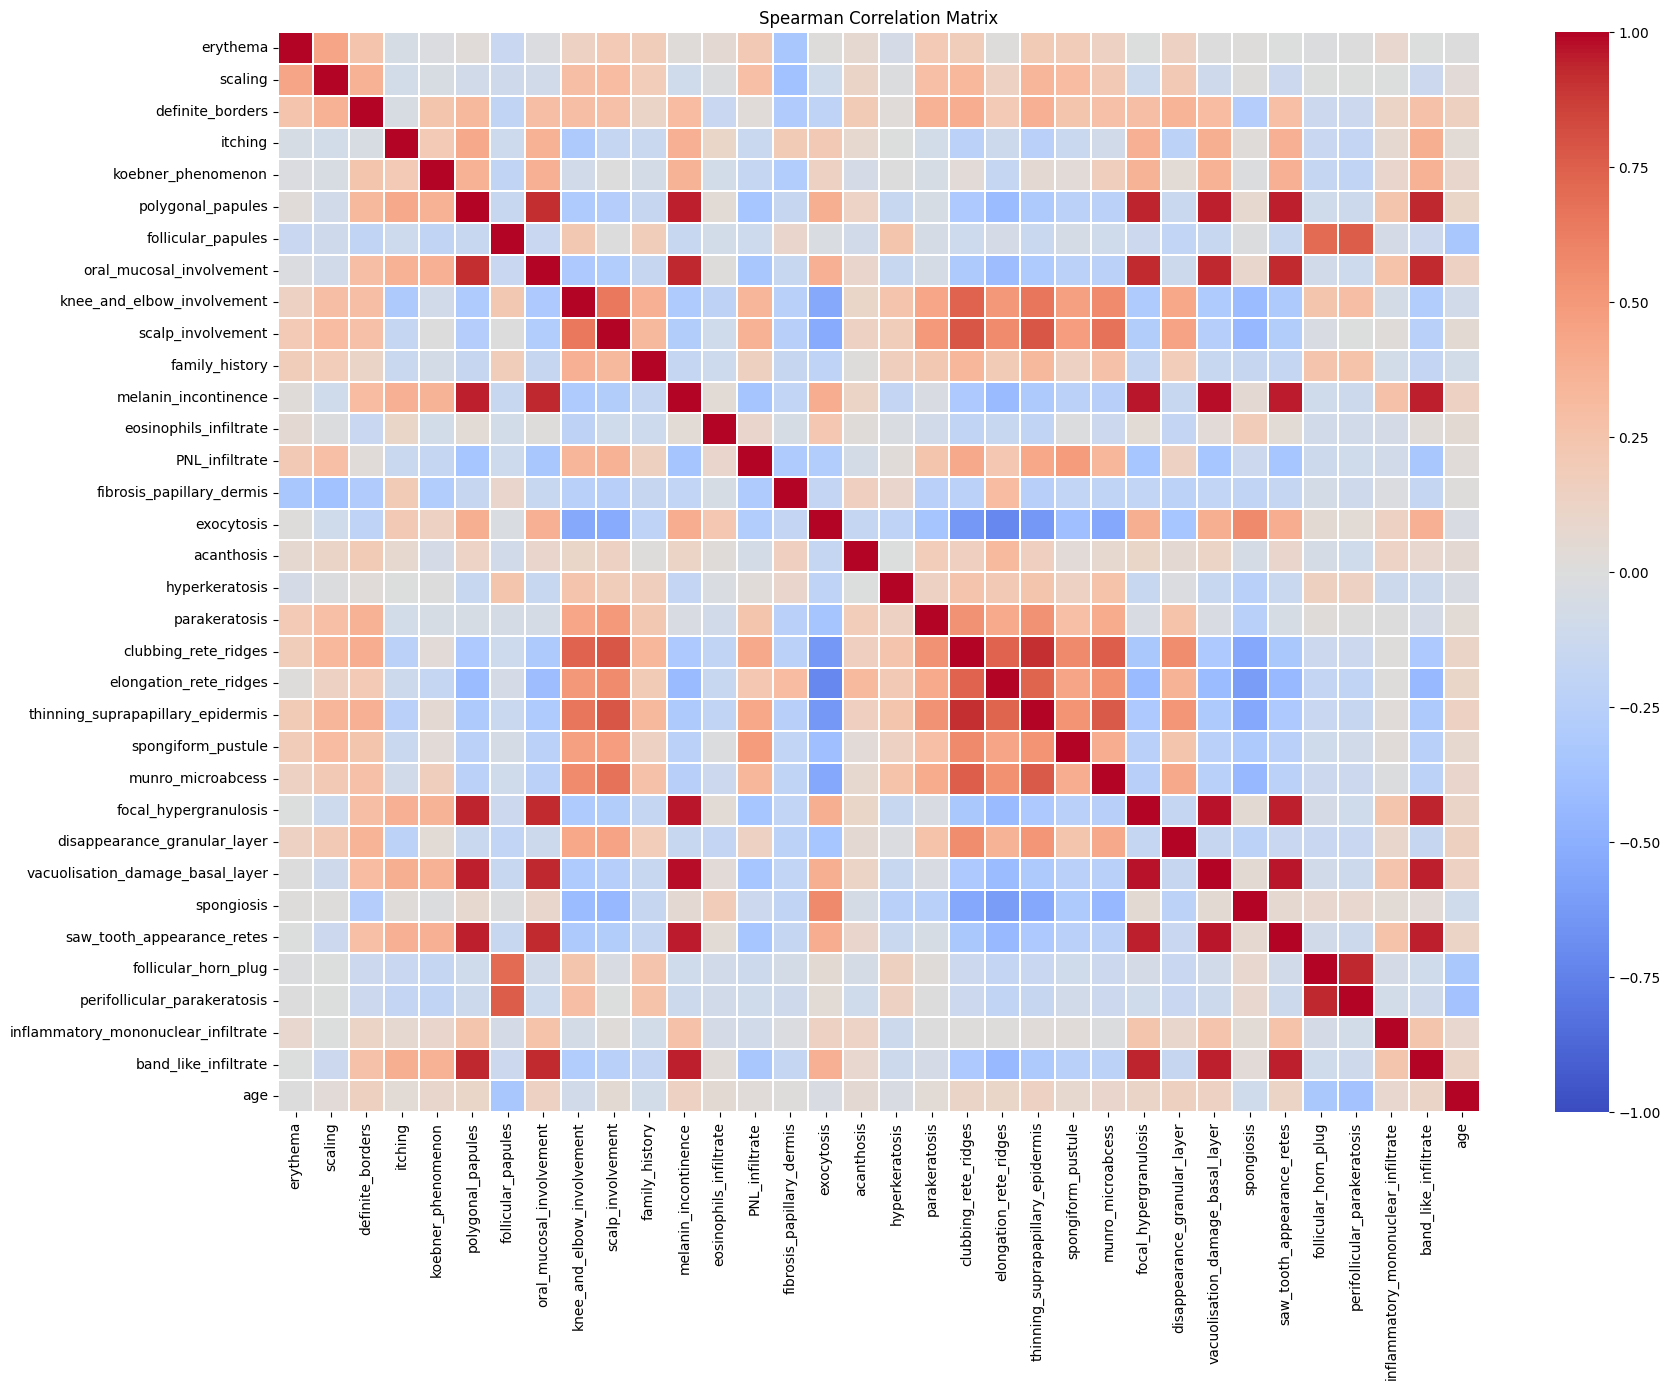

In [14]:
# Spearman correlation matrix
correlation_matrix = df_analysis.drop(
    columns=['class']
).corr(method='spearman')

# Correlation heatmap
plt.figure(figsize=(18, 14))

sns.heatmap(
    correlation_matrix,
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.2
)

plt.title('Spearman Correlation Matrix')
plt.tight_layout()
plt.show()


The Spearman correlation matrix provides an overview of the relationships between the predictive features, highlighting the following observations:

- **Strong Positive Correlations**: Several groups of histopathological features exhibit strong positive correlations, suggesting that certain clinical and microscopic characteristics tend to occur together. These relationships are particularly evident among features such as `melanin_incontinence`, `vacuolisation_damage_basal_layer`, `focal_hypergranulosis`, and `saw_tooth_appearance_retes`.
- **Correlated Feature Groups**: The matrix reveals clusters of strongly correlated attributes, particularly among histopathological characteristics. These patterns suggest that some features may capture overlapping information about specific dermatological manifestations.
- **Positive and Negative Relationships**: While several features exhibit positive correlations, other pairs show negative associations, indicating that certain characteristics tend to vary in opposite directions across the observations.

Overall, the correlation matrix reveals substantial dependencies among several predictive attributes. These relationships suggest potential redundancy within the feature space, which will be further investigated during the Feature Selection phase. However, correlation does not necessarily imply that two features are interchangeable or that one can be safely removed.

In [15]:
# Extract upper triangular correlations
upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

# Sort correlations by absolute value
strong_correlations = (
    upper_triangle.stack()
    .reset_index()
)

strong_correlations.columns = [
    'Feature 1', 'Feature 2', 'Correlation'
]

strong_correlations['Absolute Correlation'] = (
    strong_correlations['Correlation'].abs()
)

strong_correlations = strong_correlations.sort_values(
    by='Absolute Correlation',
    ascending=False
)

display(strong_correlations.head(20))


,Feature 1,Feature 2,Correlation,Absolute Correlation
322,melanin_incontinence,vacuolisation_damage_basal_layer,0.980545,0.980545
517,focal_hypergranulosis,vacuolisation_damage_basal_layer,0.969554,0.969554
320,melanin_incontinence,focal_hypergranulosis,0.966728,0.966728
534,vacuolisation_damage_basal_layer,saw_tooth_appearance_retes,0.965544,0.965544
324,melanin_incontinence,saw_tooth_appearance_retes,0.957328,0.957328
160,polygonal_papules,melanin_incontinence,0.952971,0.952971
519,focal_hypergranulosis,saw_tooth_appearance_retes,0.952122,0.952122
538,vacuolisation_damage_basal_layer,band_like_infiltrate,0.950678,0.950678
175,polygonal_papules,vacuolisation_damage_basal_layer,0.947975,0.947975
549,saw_tooth_appearance_retes,band_like_infiltrate,0.947506,0.947506


The analysis of the 20 strongest feature correlations provides a more detailed view of the relationships identified in the correlation matrix:

- **Highly Correlated Histopathological Features**: The strongest relationships are observed among histopathological attributes. In particular, `melanin_incontinence` and `vacuolisation_damage_basal_layer` exhibit the highest correlation, with a Spearman coefficient of approximately **0.981**. Similarly, `focal_hypergranulosis` and `vacuolisation_damage_basal_layer` show a correlation of approximately **0.970**.
- **Groups of Interrelated Features**: Several attributes, including `polygonal_papules`, `melanin_incontinence`, `focal_hypergranulosis`, `saw_tooth_appearance_retes`, and `band_like_infiltrate`, exhibit consistently high correlations with one another, with coefficients exceeding **0.93**. This suggests that these characteristics frequently occur together and may describe related dermatological patterns.
- **Additional Strong Relationships**: A particularly strong correlation is also observed between `follicular_horn_plug` and `perifollicular_parakeratosis` (approximately **0.931**), indicating another pair of closely associated histopathological characteristics.

Overall, the results confirm the presence of strongly correlated groups of features, particularly among histopathological attributes. This may indicate overlapping information within the dataset and should be considered during feature selection and engineering. Nevertheless, highly correlated features may still provide complementary diagnostic information, and their removal should be evaluated rather than assumed to be beneficial.

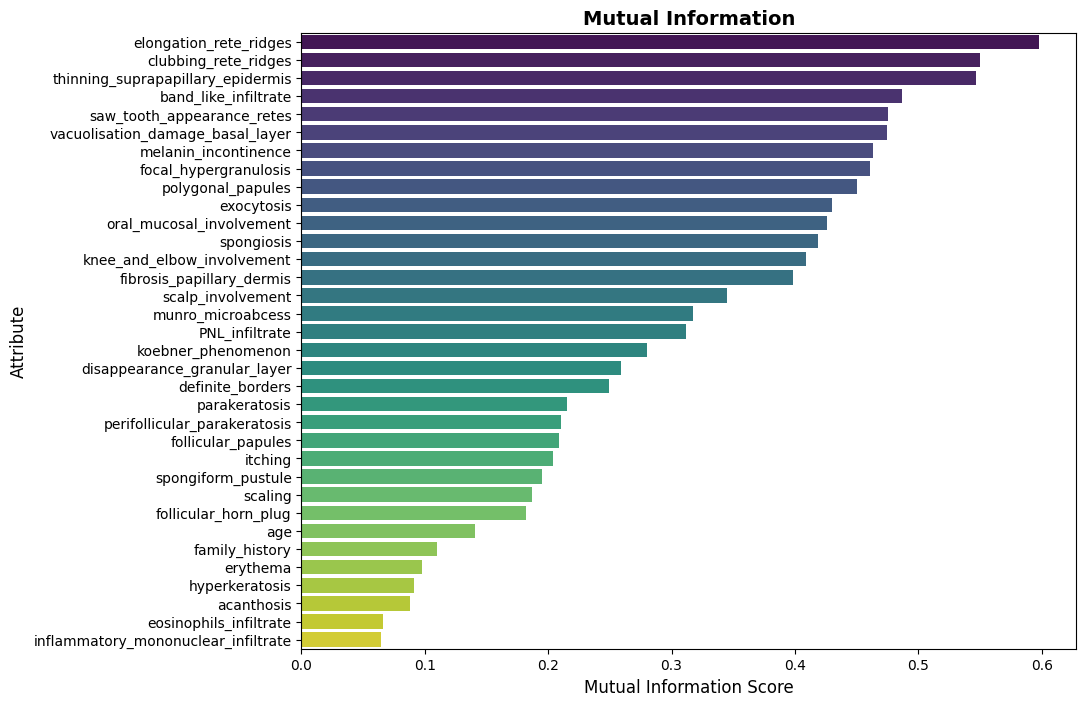

In [16]:
df_clean = df_analysis.copy()
df_clean['age'] = pd.to_numeric(df_clean['age'], errors='coerce')
df_clean['age'].fillna(df_clean['age'].median(), inplace=True)

X = df_clean.drop(columns=['class', 'class_name'], errors='ignore')
y = df_clean['class']

discrete_features_mask = [col != 'age' for col in X.columns]
mi_scores = mutual_info_classif(X, y, discrete_features=discrete_features_mask, random_state=42)
mi_series = pd.Series(mi_scores, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(x=mi_series.values, y=mi_series.index, palette='viridis')
plt.title('Mutual Information', fontsize=14, fontweight='bold')
plt.xlabel('Mutual Information Score', fontsize=12)
plt.ylabel('Attribute', fontsize=12)
plt.show()

The Mutual Information analysis evaluates the individual association between each predictive feature and the target variable, providing insights into their potential relevance for the classification task.

The results reveal the following observations:

- **Most Informative Features**: Histopathological attributes exhibit the highest Mutual Information scores. In particular, `elongation_rete_ridges` (approximately 0.60), `clubbing_rete_ridges` (0.55), and `thinning_suprapapillary_epidermis` (0.55) rank among the most informative features. Other attributes, such as `band_like_infiltrate`, `saw_tooth_appearance_retes`, and `vacuolisation_damage_basal_layer`, also show relatively high scores.
- **Histopathological vs. Clinical Features**: The ranking suggests that several histopathological characteristics provide more information about the disease category than many clinical features. In contrast, attributes such as `erythema`, `family_history`, and `age` exhibit comparatively lower Mutual Information scores.
- **Lower Informative Features**: `inflammatory_mononuclear_infiltrate` and `eosinophils_infiltrate` show the lowest scores, indicating a weaker individual association with the target variable according to this measure.

Overall, the analysis suggests that histopathological features play an important role in distinguishing between the six dermatological conditions. However, lower Mutual Information scores do not necessarily imply that a feature is irrelevant, since some attributes may provide complementary information when combined with other predictors.

These results provide an initial indication of feature relevance and will be useful during the subsequent Feature Selection phase. The final selection of predictive attributes will be evaluated within the training data to avoid data leakage.

## 2.9 Multivariate Analysis: PCA and t-SNE

While univariate and bivariate analyses examine individual features and pairwise relationships, multivariate analysis investigates the dataset by considering multiple attributes simultaneously.

In this section, two dimensionality reduction techniques are explored: Principal Component Analysis (PCA) and t-Distributed Stochastic Neighbor Embedding (t-SNE).

Both techniques project the original feature space into a lower-dimensional representation, making it possible to visualize potential patterns and relationships among observations.

The analysis focuses on:
- Exploring whether observations belonging to different dermatological classes form distinguishable groups.
- Investigating the structure and variance of the dataset in a lower-dimensional space.
- Comparing the behavior of a linear technique (PCA) with a nonlinear technique (t-SNE).

The target variable `class` is excluded from the dimensionality reduction process and is used only to color the observations in the resulting visualizations.

Since these techniques require complete numerical data, the 8 observations with missing `age` values are temporarily excluded from this exploratory analysis. No imputation or permanent modification of the original dataset is performed.

In [17]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

# Select complete observations for this exploratory analysis
df_multivariate = df_analysis.dropna(subset=['age']).copy()

# Separate predictive features and target
X = df_multivariate.drop(columns=['class'])
y = df_multivariate['class']

# Standardize predictive features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Observations used: {X_scaled.shape[0]}")
print(f"Number of features: {X_scaled.shape[1]}")

Observations used: 358
Number of features: 34


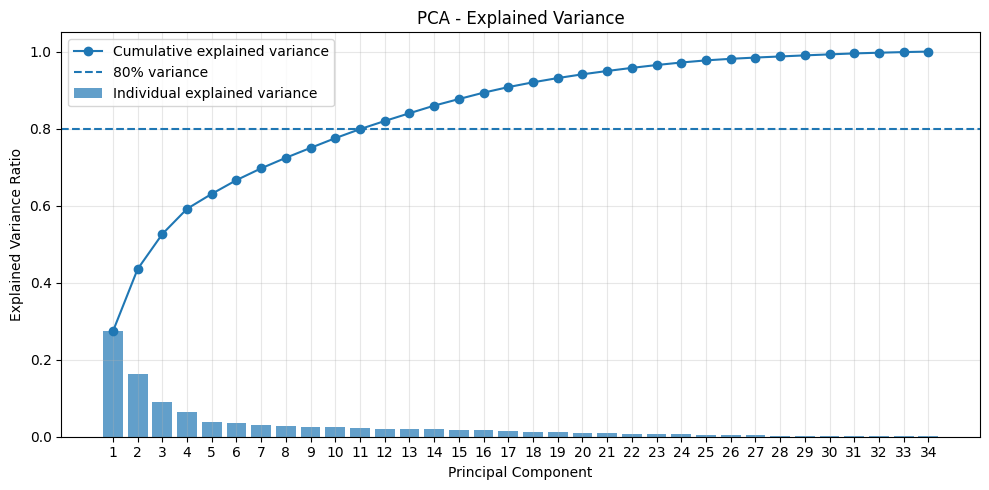

Variance explained by PC1 and PC2: 43.53%
Components needed to explain 80% of variance: 12


In [18]:
# Fit PCA
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

# Explained variance
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

# Plot explained variance
plt.figure(figsize=(10, 5))

plt.bar(
    range(1, len(explained_variance) + 1),
    explained_variance,
    alpha=0.7,
    label='Individual explained variance'
)

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker='o',
    label='Cumulative explained variance'
)

plt.axhline(y=0.80, linestyle='--', label='80% variance')

plt.xlabel('Principal Component')
plt.ylabel('Explained Variance Ratio')
plt.title('PCA - Explained Variance')
plt.xticks(range(1, len(explained_variance) + 1))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Variance explained by PC1 and PC2: "
      f"{cumulative_variance[1]:.2%}")

components_80 = np.argmax(cumulative_variance >= 0.80) + 1
print(f"Components needed to explain 80% of variance: {components_80}")

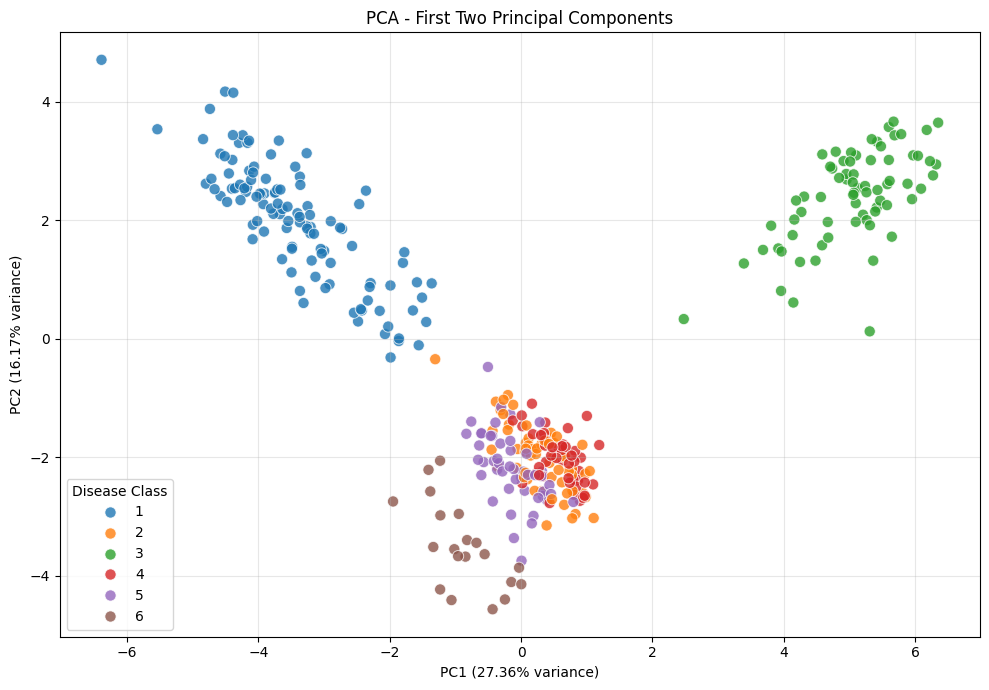

In [19]:
# Plot first two principal components
plt.figure(figsize=(10, 7))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=y,
    palette='tab10',
    s=65,
    alpha=0.8
)

plt.xlabel(f'PC1 ({explained_variance[0]:.2%} variance)')
plt.ylabel(f'PC2 ({explained_variance[1]:.2%} variance)')
plt.title('PCA - First Two Principal Components')
plt.legend(title='Disease Class')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

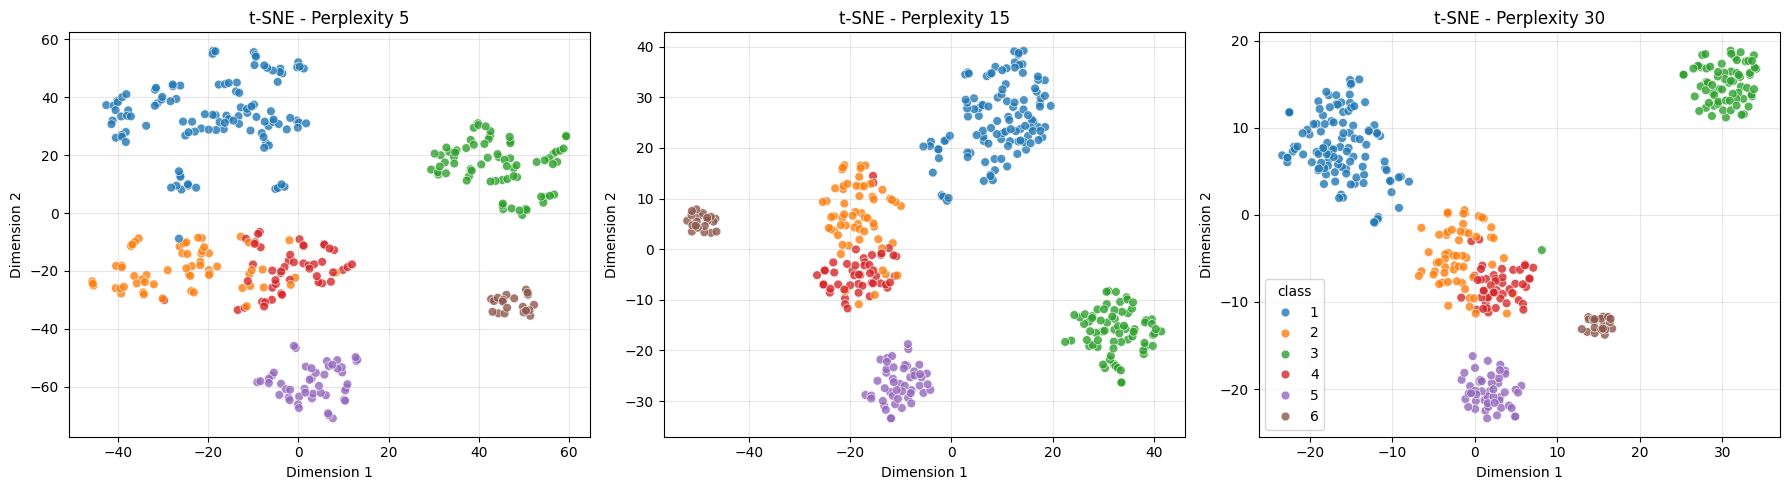

In [20]:
perplexities = [5, 15, 30]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, perplexity in zip(axes, perplexities):

    tsne = TSNE(
        n_components=2,
        perplexity=perplexity,
        random_state=42,
        init='pca',
        learning_rate='auto'
    )

    X_tsne = tsne.fit_transform(X_scaled)

    sns.scatterplot(
        x=X_tsne[:, 0],
        y=X_tsne[:, 1],
        hue=y,
        palette='tab10',
        s=40,
        alpha=0.8,
        legend=(perplexity == 30),
        ax=ax
    )

    ax.set_title(f't-SNE - Perplexity {perplexity}')
    ax.set_xlabel('Dimension 1')
    ax.set_ylabel('Dimension 2')
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

The PCA and t-SNE analyses provide complementary insights into the underlying structure of the dataset.

PCA shows that the first two principal components explain 43.53% of the total variance, while 12 components are required to retain 80% of the information. The two-dimensional projection reveals a certain degree of class separability, particularly for classes 1 and 3, whereas classes 2, 4 and 5 exhibit significant overlap.

The t-SNE visualizations provide a more detailed representation of local structures. Across the three perplexity configurations, classes 1 and 3 consistently form well-separated clusters, while classes 5 and 6 also exhibit relatively distinct distributions. Conversely, classes 2 and 4 remain partially overlapping, suggesting similarities in their feature patterns.

Overall, these findings indicate that the dataset contains meaningful patterns that can potentially support the classification task, although the degree of separability varies across disease categories. The recurring overlap between certain classes suggests that further investigation into feature relevance, redundancy and potential feature engineering strategies may be beneficial.

These observations will serve as a starting point for the subsequent data preparation and modeling phases. In particular, classification experiments will be necessary to determine whether the observed structures translate into effective predictive performance.

## 2.10 Outlier Detection

Outlier detection is performed to identify observations with potentially unusual numerical values.

Since most predictive attributes are ordinal and constrained to a predefined range, the analysis primarily focuses on the age attribute.

The Interquartile Range (IQR) method is used to identify potential outliers. These observations are flagged for further investigation rather than automatically removed, as extreme values may still represent valid patient records.

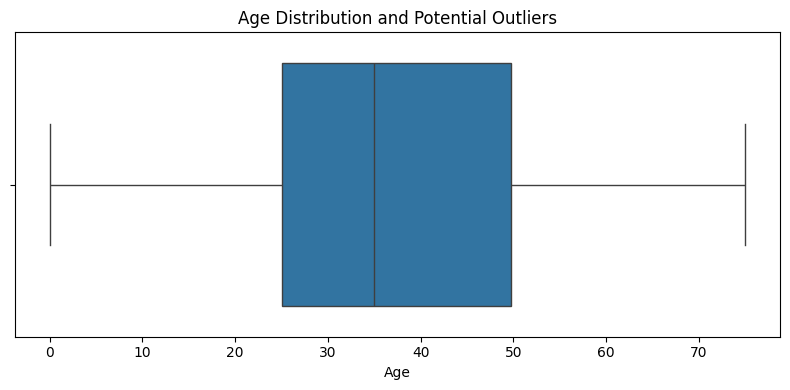

Lower bound: -12.12
Upper bound: 86.88
Number of potential outliers: 0


,age,class


In [21]:
# Age distribution
plt.figure(figsize=(8, 4))

sns.boxplot(x=df_analysis['age'])

plt.title('Age Distribution and Potential Outliers')
plt.xlabel('Age')
plt.tight_layout()
plt.show()

# IQR method
Q1 = df_analysis['age'].quantile(0.25)
Q3 = df_analysis['age'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df_analysis[
    (df_analysis['age'] < lower_bound) |
    (df_analysis['age'] > upper_bound)
]

print(f"Lower bound: {lower_bound:.2f}")
print(f"Upper bound: {upper_bound:.2f}")
print(f"Number of potential outliers: {len(outliers)}")

display(outliers[['age', 'class']])


The analysis of the `age` attribute using the Interquartile Range (IQR) method reveals the following observations:

- **Age Distribution**: The boxplot shows a relatively wide distribution of patient ages, with a median of approximately 35 years. The interquartile range extends from approximately 25 to 50 years, indicating that the central 50% of patients fall within this age interval.
- **IQR-Based Outlier Detection**: The calculated lower and upper bounds are **-12.12** and **86.88 years**, respectively. No observations fall outside these limits, indicating that no statistical outliers are identified using the IQR criterion.
- **Potential Anomalies**: Although no statistical outliers are detected, the dataset contains an observation with an age of **0 years**. This value falls within the calculated IQR boundaries and is therefore not classified as an outlier by this method. Nevertheless, it may represent a potential data quality issue that requires further investigation.

Overall, the IQR analysis does not identify any statistical outliers in the age attribute. However, the presence of an observation with an age of zero highlights the importance of distinguishing between statistical outliers and potentially invalid or unusual values. This observation will be further investigated during the Data Preparation phase, without assuming that it is necessarily incorrect.

## 2.11 Data Quality Validation

The final step of the data understanding phase consists of validating the consistency and integrity of the dataset.

The analysis verifies whether the encoded attributes respect their expected value ranges and whether the target variable contains only valid class labels.

This validation helps identify potential inconsistencies that could affect subsequent data preparation and modeling operations.

In [22]:
# Validate ordinal feature ranges
invalid_ordinal_values = {}

for col in ordinal_features:
    invalid = df_analysis[~df_analysis[col].between(0, 3)]

    if not invalid.empty:
        invalid_ordinal_values[col] = len(invalid)

# Validate family history (binary feature)
invalid_family_history = (
    ~df_analysis['family_history'].isin([0, 1])
).sum()

# Validate target classes
valid_classes = [1, 2, 3, 4, 5, 6]

invalid_classes = (
    ~df_analysis['class'].isin(valid_classes)
).sum()

print("Data Validation Results")
print("-----------------------")
print(f"Invalid ordinal values: {sum(invalid_ordinal_values.values())}")
print(f"Invalid family history values: {invalid_family_history}")
print(f"Invalid target values: {invalid_classes}")


Data Validation Results
-----------------------
Invalid ordinal values: 0
Invalid family history values: 0
Invalid target values: 0


The data validation process verifies whether the predictive attributes respect their expected value ranges and whether the target variable contains valid class labels. The analysis reveals the following observations:

- **Ordinal Feature Validation**: All ordinal features contain valid values within the expected range of `0` to `3`. No invalid values are detected.
- **Binary Feature Validation**: The `family_history` attribute contains only the expected binary values (`0` and `1`), with no inconsistencies identified.
- **Target Variable Validation**: All observations belong to one of the six expected disease categories (classes `1` to `6`). No invalid class labels are detected.

Overall, the validation confirms that all evaluated attributes respect their predefined value constraints. No domain-related inconsistencies are identified in the ordinal features, the binary attribute or the target variable.

However, these results do not imply that the dataset is entirely free of data quality issues. The 8 missing values in `age` and the observation with an age of `0` identified in the previous analyses still require consideration during the Data Preparation phase.

# 3. Data Preparation

The Data Preparation phase aims to improve the quality and suitability of the dataset for the subsequent modeling activities.

Based on the findings obtained during the Data Understanding phase, several aspects require further investigation and potentially appropriate treatment:

- Missing values in the `age` attribute.
- A potentially anomalous observation with an age of 0 years.
- Strong correlations and potential redundancy among histopathological features.
- Different levels of feature relevance with respect to the target variable.
- Class imbalance, particularly affecting Pityriasis Rubra Pilaris.

The following activities address these issues through data cleaning, feature engineering, feature selection and dataset optimization.

All transformations will be performed while preserving the original dataset, allowing comparisons between alternative data preparation strategies.

# 3.1 Data Encoding

The Dermatology dataset is already largely encoded numerically. Its clinical and histopathological attributes are represented using ordinal values, while `family_history` is binary and `age` is a continuous numerical variable.

Therefore, no additional encoding transformations are required:

- Ordinal attributes already use numerical values that preserve their natural ordering.
- `family_history` is already represented as a binary variable (0/1).
- `age` is already numerical.
- The target variable `class` is represented through six numerical class labels and will be treated as the classification target.

In conclusion, the existing representations are suitable for the dataset, and applying additional encoding techniques would be unnecessary.

## 3.2 Data Cleaning

### 3.2.1 Missing Value Handling

As identified during the Data Understanding phase, the dataset contains 8 missing values, all affecting the `age` attribute, corresponding to approximately 2.19% of the observations.

To address this issue, **Median Imputation** is adopted as the missing value handling strategy.

The median is preferred over the mean because it is less sensitive to extreme observations and provides a robust estimate of central tendency.

This approach allows all observations to be preserved while ensuring that the `age` attribute contains no missing values.

In [23]:
# Convert '?' into NaN
df['age'] = df['age'].replace('?', np.nan)

# Convert age to numeric
df['age'] = pd.to_numeric(df['age'])

# Calculate median
age_median = df['age'].median()

# Apply median imputation
df['age'] = df['age'].fillna(age_median)

# Verify results
print(f"Median used: {age_median:.2f}")
print(f"Remaining missing values: {df['age'].isnull().sum()}")
print(f"Dataset dimensions: {df.shape}")

Median used: 35.00
Remaining missing values: 0
Dataset dimensions: (366, 35)


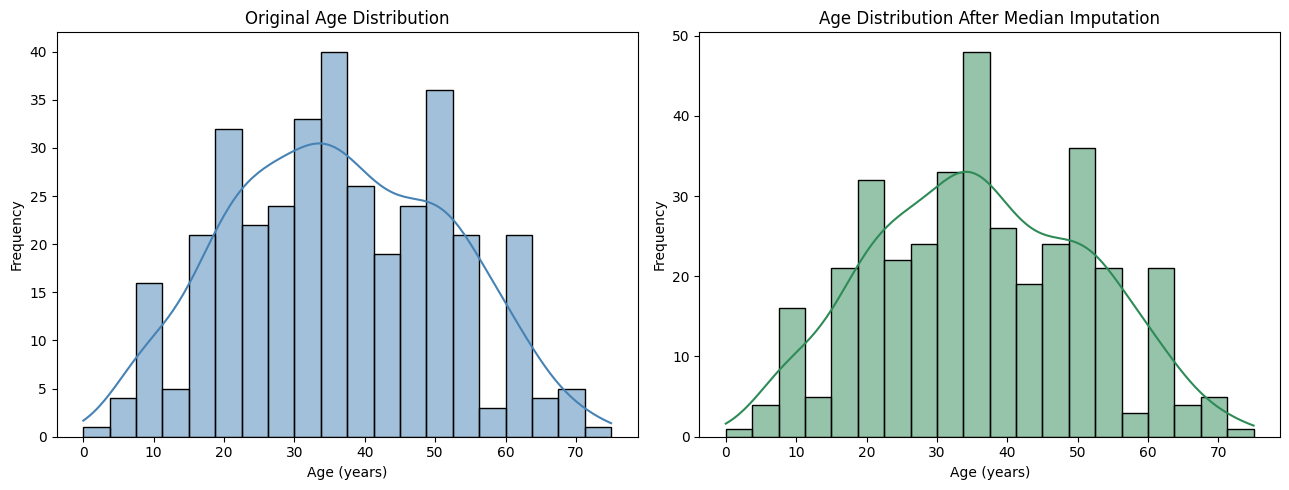

In [24]:
# Compare age distributions before and after imputation

age_comparison = pd.DataFrame({
    'Original (Available Values)': df_analysis['age'],
    'After Median Imputation': df['age']
})

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(
    df_analysis['age'].dropna(),
    bins=20,
    kde=True,
    ax=axes[0],
    color='steelblue'
)

axes[0].set_title('Original Age Distribution')
axes[0].set_xlabel('Age (years)')
axes[0].set_ylabel('Frequency')

sns.histplot(
    df['age'],
    bins=20,
    kde=True,
    ax=axes[1],
    color='seagreen'
)

axes[1].set_title('Age Distribution After Median Imputation')
axes[1].set_xlabel('Age (years)')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

In [25]:
# Compare age distribution before and after median imputation

age_comparison = pd.DataFrame({
    'Before Imputation': df_analysis['age'].describe(),
    'After Imputation': df['age'].describe()
})

age_comparison.loc['skewness'] = [
    f'{df_analysis['age'].skew():.2f}',
    f'{df['age'].skew():.2f}'
]

age_comparison.loc['kurtosis'] = [
    f'{df_analysis['age'].kurt():.2f}',
    f'{df['age'].kurt():.2f}'
]

display(age_comparison)

,Before Imputation,After Imputation
count,358.0,366.0
mean,36.296089,36.26776
std,15.324557,15.156875
min,0.0,0.0
25%,25.0,25.0
50%,35.0,35.0
75%,49.75,48.0
max,75.0,75.0
skewness,0.07,0.08
kurtosis,-0.71,-0.66


The comparison shows that median imputation had a limited impact on the statistical distribution of `age`.

The number of valid observations increased from 358 to 366, ensuring that all records were retained. The mean decreased slightly from 36.30 to 36.27, while the median remained unchanged at 35.

A small reduction in standard deviation (from 15.32 to 15.16) and interquartile range (from 24.75 to 23) was observed, reflecting the increased concentration of values around the median due to imputation.

Skewness and kurtosis also remained very similar before and after imputation, indicating that the overall shape of the distribution was largely preserved.

Overall, median imputation successfully addressed the missing values while introducing only minor changes to the statistical properties of the `age` variable.

### 3.2.2 Potential Anomalies Investigation

In this section we analyize wheather the 0-value in `age` is an anomalous or not.

In [26]:
# Identify records with age equal to zero
zero_age_records = df[df['age'] == 0]
print(f"Number of records with age = 0: {len(zero_age_records)}")

Number of records with age = 0: 1


The investigation identifies one observation with an age of zero years. Although this value may appear unusual, it does not exceed the IQR-based outlier boundaries and cannot be automatically classified as invalid.

Since the available dataset documentation does not provide sufficient information to determine whether this value represents a valid age or a recording error, the observation is retained without modification.

This decision avoids introducing unsupported assumptions or removing potentially valid patient information.

## 3.3 Data Scaling

The dataset contains features with different numerical ranges:

- `age` is a continuous numerical attribute, with values ranging from 0 to 75.
- Clinical and histopathological attributes are ordinal and already share the same range (0–3).
- `family_history` is a binary attribute (0/1).

Since the ordinal attributes already share a common scale and their numerical values represent ordered levels, applying an additional scaling transformation to all features is not necessarily beneficial.

Therefore, the following strategy is adopted:

- Apply **StandardScaler** to `age`, transforming it to have zero mean and unit variance.
- Leave ordinal attributes unchanged, preserving their original interpretation and ordering.
- Leave `family_history` unchanged, as it is already binary.
- Do not scale the target variable `class`.


In [27]:
# Keep the original missing values here: imputation will be learned inside each pipeline.
X = df_analysis.drop(columns=['class', 'class_name'], errors='ignore').copy()
X['age'] = pd.to_numeric(X['age'], errors='coerce')
y = df_analysis['class'].astype(int)

# Split data into training and test sets.
# The test set is held out and will only be used for the final evaluation.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=1/3,
    stratify=y,
    random_state=42
)

print(f"Training set: {X_train.shape[0]} records ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"Test set: {X_test.shape[0]} records ({X_test.shape[0]/len(X)*100:.1f}%)")
print(f"Missing age values in training set: {X_train['age'].isna().sum()}")
print(f"Missing age values in test set: {X_test['age'].isna().sum()}")


Training set: 244 records (66.7%)
Test set: 122 records (33.3%)
Missing age values in training set: 3
Missing age values in test set: 5


## 3.4 Feature Selection
The exploratory analysis identified two main aspects that should be considered during feature selection:
- Several histopathological attributes show a strong individual association with the disease class, according to Mutual Information.
- Some histopathological attributes are strongly correlated with each other, suggesting that part of their information may be redundant.
Feature selection is therefore treated as an empirical model-selection task rather than a manual deletion based only on prevalence or individual Mutual Information scores. Rare attributes are not automatically removed, since they may be particularly informative for a specific disease.

The following experiments compare:
1. Baseline: all original predictive features.
2. Filter method: VarianceThreshold followed by SelectKBest using Mutual Information.
3. Wrapper method (RFE): Recursive Feature Elimination with a decision tree as the feature-ranking estimator.
4. Wrapper method (SFS): Sequential Forward Selection, evaluated using cross-validation.
The selection procedures and preprocessing operations are fitted inside each cross-validation fold. This is important to avoid data leakage. The test set remains untouched until the final evaluation.

Balanced Accuracy and Macro F1-score are used because the target contains six classes and is not perfectly balanced.

In [33]:
# Feature selection: compare four strategies

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold, SelectKBest, mutual_info_classif, RFE, SequentialFeatureSelector
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
from sklearn.base import clone

# Preprocessing: impute and scale age; keep ordinal features unchanged.
age_cols = ['age']
other_cols = [c for c in X_train.columns if c != 'age']

preprocessor = ColumnTransformer([
    ('age', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), age_cols),
    ('ordinal', 'passthrough', other_cols)
], verbose_feature_names_out=False)

# Mutual Information: age is continuous, the other attributes are discrete.
def mi_score(X, y):
    discrete = [False] + [True] * (X.shape[1] - 1)
    return mutual_info_classif(X, y, discrete_features=discrete, random_state=42)

tree = DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=42)
model = RandomForestClassifier(
    n_estimators=300, class_weight='balanced', random_state=42, n_jobs=-1
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# All selectors are part of the pipeline, so they are refitted within each fold.
pipelines = {
    'Baseline (34)': Pipeline([
        ('prep', clone(preprocessor)),
        ('model', clone(model))
    ]),
    'SelectKBest (15)': Pipeline([
        ('prep', clone(preprocessor)),
        ('variance', VarianceThreshold()),
        ('select', SelectKBest(mi_score, k=15)),
        ('model', clone(model))
    ]),
    'RFE (15)': Pipeline([
        ('prep', clone(preprocessor)),
        ('variance', VarianceThreshold()),
        ('select', RFE(clone(tree), n_features_to_select=15)),
        ('model', clone(model))
    ]),
    'SFS (15)': Pipeline([
        ('prep', clone(preprocessor)),
        ('variance', VarianceThreshold()),
        ('select', SequentialFeatureSelector(
            clone(tree), n_features_to_select=15, direction='forward',
            scoring='balanced_accuracy',
            cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
            n_jobs=-1
        )),
        ('model', clone(model))
    ])
}

scores = {'balanced_accuracy': 'balanced_accuracy', 'macro_f1': 'f1_macro', 'accuracy': 'accuracy'}
results = []

for name, pipe in pipelines.items():
    cv_scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scores, n_jobs=1)
    results.append({
        'Experiment': name,
        'Balanced Accuracy': cv_scores['test_balanced_accuracy'].mean(),
        'BA std': cv_scores['test_balanced_accuracy'].std(),
        'Macro F1': cv_scores['test_macro_f1'].mean(),
        'F1 std': cv_scores['test_macro_f1'].std(),
        'Accuracy': cv_scores['test_accuracy'].mean()
    })

results_df = pd.DataFrame(results).sort_values('Balanced Accuracy', ascending=False)
display(results_df.round(3))

,Experiment,Balanced Accuracy,BA std,Macro F1,F1 std,Accuracy
0,Baseline (34),0.951,0.032,0.957,0.026,0.963
3,SFS (15),0.935,0.042,0.940,0.037,0.947
2,RFE (15),0.884,0.052,0.884,0.049,0.898
1,SelectKBest (15),0.856,0.059,0.846,0.059,0.873


Selected strategy: Baseline (34)
Test accuracy:          0.975
Test balanced accuracy: 0.973
Test macro F1:          0.972
\n               precision    recall  f1-score   support

           1      1.000     1.000     1.000        37
           2      0.947     0.900     0.923        20
           3      1.000     1.000     1.000        24
           4      0.882     0.938     0.909        16
           5      1.000     1.000     1.000        18
           6      1.000     1.000     1.000         7

    accuracy                          0.975       122
   macro avg      0.972     0.973     0.972       122
weighted avg      0.976     0.975     0.975       122

Number of features: 34
Selected features: ['age', 'erythema', 'scaling', 'definite_borders', 'itching', 'koebner_phenomenon', 'polygonal_papules', 'follicular_papules', 'oral_mucosal_involvement', 'knee_and_elbow_involvement', 'scalp_involvement', 'family_history', 'melanin_incontinence', 'eosinophils_infiltrate', 'PNL_infiltrate

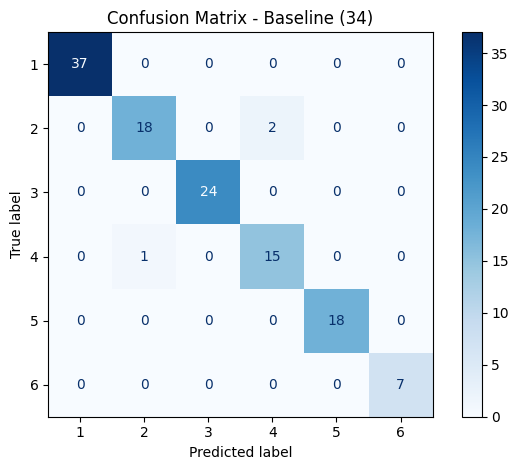

In [34]:
# Fit the best strategy and evaluate it on the held-out test set.

best_name = results_df.iloc[0]['Experiment']
best_pipe = clone(pipelines[best_name]).fit(X_train, y_train)
pred = best_pipe.predict(X_test)

print("Selected strategy:", best_name)
print(f"Test accuracy:          {accuracy_score(y_test, pred):.3f}")
print(f"Test balanced accuracy: {balanced_accuracy_score(y_test, pred):.3f}")
print(f"Test macro F1:          {f1_score(y_test, pred, average='macro'):.3f}")
print("\\n", classification_report(y_test, pred, digits=3, zero_division=0))

# Print the selected feature names.
all_names = best_pipe.named_steps['prep'].get_feature_names_out()

if 'select' in best_pipe.named_steps:
    names = all_names[best_pipe.named_steps['variance'].get_support()]
    names = names[best_pipe.named_steps['select'].get_support()]
else:
    names = all_names

print("Number of features:", len(names))
print("Selected features:", list(names))

ConfusionMatrixDisplay.from_predictions(y_test, pred, cmap='Blues', values_format='d')
plt.title(f'Confusion Matrix - {best_name}')
plt.tight_layout()
plt.show()